# 04 — Forecast experiments: FX in shocks, noise floor, simple combinations

## Summary (Sprint 3, part B)

**The FX feature lowers forecast error beyond what a time-shifted FX series achieves clearly in the 2015-16 franc shock, narrowly after covid, and not in 2011-12. No single origin market passes the market-level tests.**

| Window | Naive | Without FX | With FX | FX gain | Shifted-FX 95th pct | p (20 shifts) | FX better in | Rule verdict |
|---|---|---|---|---|---|---|---|---|
| Post-covid 2023-2026 (57 series) | 8.7 | 8.3 | 8.2 | +0.16 | +0.14 | 0.095 | 5/6 h | improves |
| Shock 2015-2016 (49 series) | 8.8 | 8.0 | 7.6 | +0.36 | +0.06 | 0.048 | 6/6 h | improves |
| Shock 2011-2012 (49 series) | 9.6 | 8.5 | 8.4 | +0.08 | +0.34 | 0.381 | 3/6 h | no measurable gain |

WAPE in %, all horizons; FX gain = WAPE without FX minus WAPE with FX, in points.

- **2015-16 (SNB floor removed):** the real FX gain (+0.36) is above all 20 shifted-FX gains (highest +0.07) and the model with FX has the lowest WAPE at every horizon; in peak season the gain is +0.60. Germany, the market most linked to EUR/CHF in notebook 02, goes from 10.7% to 9.2% (+1.49).
- **Post-covid:** the gain (+0.16) passes the pre-set rule (above the 95th percentile, positive in 5/6 horizons) but only just: 1 of the 20 shifts does better (p = 0.095). The shifted FX series also lower WAPE by +0.06 at the median, which fits notebook 03's Swiss placebo: part of the gain comes from adding any slow-moving feature, not from the exchange rate.
- **2011-12 (floor introduced Sep 2011):** +0.08, below the noise floor (+0.34); FX helps Germany (+1.24) and Italy (+0.84) but hurts the United Kingdom (-1.31) and China (-2.34).
- **By origin market:** no market passes both its own noise floor and the Diebold-Mariano test in any window; the lowest unadjusted DM p is 0.09, so this is not only an effect of the Holm adjustment. With 16-43 target months per window the test has little power.
- **Simple combinations** ((naive + model) / 2): after covid they beat both of their parts at h = 2-6; at h = 6 the combination with FX has WAPE 8.3% vs 8.7% naive and 8.6% for the model with FX. In both shock windows they never beat both parts, because the naive is far behind there (8.8% and 9.6%).

All rules were fixed before the experiments were run (see next cell). Every number above is checked by the last code cell ("Summary check").


## Rules (fixed before the experiments were run)

Same models, features, hyperparameters and metrics as notebook 03 (part A). No tuning, no extra FX variants.

**Test windows** (rolling origin, origin = target - h, training only on rows whose target month is <= the origin):

| Window | Target months | Series | Peak-season months from |
|---|---|---|---|
| Post-covid (part A) | Jan 2023 - Jul 2026 (43) | 57 | 2013-2019 |
| Shock 2015 | Jan 2015 - Dec 2016 (24) | 49 canton x origin | 2005-2010 |
| Shock 2011 | Sep 2011 - Dec 2012 (16) | 49 canton x origin | 2005-2010 |

Resort series start in 2013, so they are left out of the shock windows. Peak months for the shock windows come from 2005-2010, i.e. before the test.

**1. Shock backtest.** WAPE of seasonal naive / model without FX / model with FX, overall, by horizon, by origin market, in peak season.

**2. Noise floor.** The model with FX is refit 20 times with the FX feature **circularly shifted** in time (seeds 0-19; shift k drawn between 24 months and series length - 24; the same k for all 4 currencies, in training and test). *Why a circular shift and not a plain shuffle:* a shuffle turns FX into white noise, which trees can easily ignore, so the noise floor would be too easy to beat. A shift keeps FX's autocorrelation, its trends and the co-movement between currencies, and only breaks its link with the calendar: it is the strictest fair placebo.
- Shifted gain = WAPE without FX - WAPE with shifted FX. Empirical p = (1 + #{shifted gain >= real gain}) / 21.
- **FX "improves forecasts in a window"** only if the overall real gain is above the 95th percentile of the 20 shifted gains **and** the gain is positive in at least 4 of 6 horizons.
- **Diebold-Mariano** per origin market (model without FX vs with FX): monthly loss gap = sum of (|error without FX| - |error with FX|) over the market's series and 6 horizons / sum of actuals; Newey-West variance (5 lags), Harvey-Leybourne-Newbold correction, two-sided; **Holm** adjustment across markets within each window.
- **A market "benefits from FX"** only if its real gain beats its own shifted 95th percentile **and** its Holm-adjusted DM p < 0.05.

**3. Simple combinations.** (naive + model without FX) / 2 and (naive + model with FX) / 2, in nights, no weights. A combination "helps at horizon h" if its WAPE is below both of its parts.

*Disclosure:* while smoke-testing the script, one target month of the 2011 window (Sep 2011) was scored before the full run; the rules above were already fixed and were not changed.

Everything else is reported as "no measurable gain". Language is descriptive: nothing here measures a causal effect of the franc.

**Runtime.** About 11,000 model fits, run by `python src/run_experiments.py` (4 workers; 6,277 s, about 1 h 45 min, on a 4-core Intel Mac) and cached in `data/processed/experiments/`. This notebook only reads the cache and **fails if the cache's fingerprint** (code, data, settings) does not match the current files. Backend: scikit-learn's `HistGradientBoostingRegressor` (LightGBM could not be installed on this machine).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
from charts import (GREY, INK, INK_SOFT, ORIGIN_COLORS, SLOTS, SOURCE_BFS, SOURCE_BFS_SNB, add_source,
                    connect, save, set_style)
import forecast as fc
import run_experiments as rx

set_style()
pd.set_option("display.precision", 2)

meta = json.loads((rx.OUT / "fingerprint.json").read_text())
assert meta["fingerprint"] == rx.fingerprint(), \
    "cached results do not match the current code/data: re-run python src/run_experiments.py"
print(f"Cache OK (fingerprint {meta['fingerprint'][:12]}..., computed {meta['finished']}, {meta['seconds']}s)")

con = connect()
panel = fc.load_panel(con)
con.close()
WIN = list(rx.WINDOWS)
LABEL = {"post_covid": "Post-covid 2023-2026", "shock_2015": "Shock 2015-2016", "shock_2011": "Shock 2011-2012"}
base, shifts = {}, {}
for w in WIN:
    b = pd.read_csv(rx.OUT / f"base_{w}.csv", parse_dates=["target_date", "origin_date"])
    b = fc.add_combinations(b)
    b["month"] = b["target_date"].dt.month
    peak = fc.peak_months(rx.window_panel(panel, w), years=tuple(rx.WINDOWS[w]["peak_years"]))
    b = b.merge(peak, on=["series_id", "month"], how="left").fillna({"peak": False})
    b["market"] = np.where(b["level"] == "resort", "Resort totals", b["origin"])
    s = pd.read_csv(rx.OUT / f"shifts_{w}.csv", parse_dates=["target_date"])
    s = s.merge(b[["series_id", "h", "target_date", "actual", "gb_no_fx", "market"]],
                on=["series_id", "h", "target_date"], how="left")
    assert s["actual"].notna().all() and s["seed"].nunique() == rx.N_SHIFTS
    assert len(b) == rx.window_panel(panel, w)["series_id"].nunique() * len(rx.targets(w)) * 6
    base[w], shifts[w] = b, s
    ks = sorted(meta["shifts_k"][w].values())
    print(f"{LABEL[w]:<22} {len(b):>6,} forecasts | {b['series_id'].nunique()} series | "
          f"{b['target_date'].nunique()} target months | shifts k = {ks[0]}..{ks[-1]} months")

# The post-covid base run must reproduce notebook 03 exactly
pc = fc.wape_table(base["post_covid"], []).iloc[0]
assert (round(pc.naive, 2), round(pc.gb_no_fx, 2), round(pc.gb_fx, 2)) == (8.74, 8.33, 8.17), "differs from part A"
print("Post-covid base run reproduces notebook 03 (WAPE 8.74 / 8.33 / 8.17).")

Cache OK (fingerprint 136573e96480..., computed 2026-10-21 20:21, 6277s)


Post-covid 2023-2026   14,706 forecasts | 57 series | 43 target months | shifts k = 49..207 months


Shock 2015-2016         7,056 forecasts | 49 series | 24 target months | shifts k = 49..207 months


Shock 2011-2012         4,704 forecasts | 49 series | 16 target months | shifts k = 49..207 months
Post-covid base run reproduces notebook 03 (WAPE 8.74 / 8.33 / 8.17).


## 1. Shock backtest: does FX help when the franc moves sharply?

In [2]:
ALL = list(fc.MODELS) + list(fc.COMBOS)
overall = pd.concat([fc.wape_table(base[w], [], ALL).assign(window=LABEL[w], months="all") for w in WIN] +
                    [fc.wape_table(base[w][base[w]["peak"]], [], ALL).assign(window=LABEL[w], months="peak")
                     for w in WIN]).set_index(["window", "months"])
display(overall[ALL + ["fx_gain", "n"]])
for w in WIN:
    r = overall.loc[(LABEL[w], "all")]
    print(f"{LABEL[w]:<22} WAPE naive {r.naive:5.2f}% | without FX {r.gb_no_fx:5.2f}% | with FX {r.gb_fx:5.2f}% "
          f"| FX gain {r.fx_gain:+.2f} pts")

,,naive,gb_no_fx,gb_fx,combo_no_fx,combo_fx,fx_gain,n
window,months,,,,,,,
Post-covid 2023-2026,all,8.74,8.33,8.17,8.12,8.05,0.16,14706
Shock 2015-2016,all,8.83,8.01,7.65,8.24,8.03,0.36,7056
Shock 2011-2012,all,9.64,8.48,8.39,8.83,8.72,0.08,4704
Post-covid 2023-2026,peak,8.47,8.39,8.12,8.04,7.89,0.27,3678
Shock 2015-2016,peak,9.00,8.21,7.61,8.41,8.09,0.60,1764
Shock 2011-2012,peak,10.63,8.78,8.68,9.46,9.36,0.10,1098


Post-covid 2023-2026   WAPE naive  8.74% | without FX  8.33% | with FX  8.17% | FX gain +0.16 pts
Shock 2015-2016        WAPE naive  8.83% | without FX  8.01% | with FX  7.65% | FX gain +0.36 pts
Shock 2011-2012        WAPE naive  9.64% | without FX  8.48% | with FX  8.39% | FX gain +0.08 pts


In [3]:
MARKET_ORDER = ["Switzerland", "Germany", "France", "Italy", "United Kingdom", "United States", "China",
                "Resort totals"]
by_market = {w: fc.wape_table(base[w], ["market"]).set_index("market")
             .reindex([m for m in MARKET_ORDER if m in set(base[w]["market"])]) for w in WIN}
display(pd.concat({LABEL[w]: by_market[w][["naive", "gb_no_fx", "gb_fx", "fx_gain"]] for w in WIN}, axis=1))

Post-covid 2023-2026                         Shock 2015-2016  \
                              naive gb_no_fx  gb_fx fx_gain           naive   
market                                                                        
Switzerland                    6.21     6.62   6.31    0.31            6.17   
Germany                        9.62     9.92   9.89    0.03           13.63   
France                         8.04     8.11   8.09    0.02           10.07   
Italy                         11.71    11.97  11.98   -0.01           13.91   
United Kingdom                13.65    11.97  12.34   -0.37            7.56   
United States                 13.65     9.36   9.44   -0.07            8.43   
China                         34.24    27.50  27.64   -0.14           24.73   
Resort totals                  8.00     8.38   8.20    0.18             NaN   

                                       Shock 2011-2012                          
               gb_no_fx  gb_fx fx_gain           naive gb_no_fx  gb_fx fx_gain  
market                                                                          
Switzerland        5.87   5.90   -0.03            5.69     5.74   5.77   -0.03  
Germany           10.70   9.21    1.49           17.36    13.96  12.72    1.24  
France             9.59   9.23    0.36           10.47     9.82   9.65    0.17  
Italy             12.62  12.42    0.19           13.82    11.64  10.80    0.84  
United Kingdom     7.41   7.38    0.03           13.73     9.45  10.76   -1.31  
United States      7.79   7.11    0.68            9.47     9.46   9.29    0.17  
China             22.17  20.31    1.85           26.43    19.55  21.89   -2.34  
Resort totals       NaN    NaN     NaN             NaN      NaN    NaN     NaN

## 2. Noise floor: real FX gain vs 20 circularly shifted FX series

In [4]:
def gains_by(w, by):
    """Real FX gain and the 20 shifted gains, overall (by=[]) or per group."""
    b, s = base[w], shifts[w]
    real = fc.wape_table(b, by, ["gb_no_fx", "gb_fx"])
    sh = s.groupby(["seed", *by]).apply(
        lambda g: fc.wape(g["actual"], g["gb_no_fx"]) - fc.wape(g["actual"], g["gb_fx"]), include_groups=False)
    sh = sh.rename("shift_gain").reset_index()
    return real, sh

noise = {}
for w in WIN:
    real, sh = gains_by(w, [])
    g = real["fx_gain"].iloc[0]
    p95 = float(np.percentile(sh["shift_gain"], 95))
    p_emp = (1 + int((sh["shift_gain"] >= g).sum())) / (1 + rx.N_SHIFTS)
    by_h = fc.wape_table(base[w], ["h"], ["gb_no_fx", "gb_fx"])
    n_pos_h = int((by_h["fx_gain"] > 0).sum())
    noise[w] = {"real_gain": g, "shift_p95": p95, "shift_max": sh["shift_gain"].max(),
                "shift_median": sh["shift_gain"].median(), "p_emp": p_emp, "pos_horizons": n_pos_h,
                "fx_improves": bool(g > p95 and n_pos_h >= 4), "shift_gains": sh["shift_gain"].to_numpy()}
noise_tab = pd.DataFrame(noise).T.drop(columns="shift_gains").rename(index=LABEL)
display(noise_tab)
for w in WIN:
    n = noise[w]
    print(f"{LABEL[w]:<22} real FX gain {n['real_gain']:+.2f} pts vs shifted 95th pct {n['shift_p95']:+.2f} "
          f"(median {n['shift_median']:+.2f}); p = {n['p_emp']:.3f}; positive in {n['pos_horizons']}/6 horizons "
          f"-> {'FX improves forecasts' if n['fx_improves'] else 'no measurable gain'}")

,real_gain,shift_p95,shift_max,shift_median,p_emp,pos_horizons,fx_improves
Post-covid 2023-2026,0.16,0.14,0.21,0.06,0.1,5,True
Shock 2015-2016,0.36,0.06,0.07,-0.08,0.05,6,True
Shock 2011-2012,0.08,0.34,0.67,-0.12,0.38,3,False


Post-covid 2023-2026   real FX gain +0.16 pts vs shifted 95th pct +0.14 (median +0.06); p = 0.095; positive in 5/6 horizons -> FX improves forecasts
Shock 2015-2016        real FX gain +0.36 pts vs shifted 95th pct +0.06 (median -0.08); p = 0.048; positive in 6/6 horizons -> FX improves forecasts
Shock 2011-2012        real FX gain +0.08 pts vs shifted 95th pct +0.34 (median -0.12); p = 0.381; positive in 3/6 horizons -> no measurable gain


Per origin market: real gain vs its own shifted 95th percentile, and a Diebold-Mariano test (Holm-adjusted within each window).

In [5]:
mk_rows = []
for w in WIN:
    real, sh = gains_by(w, ["market"])
    dm = {}
    for m, g in base[w].groupby("market"):
        dm[m] = fc.dm_test(fc.loss_differential(g, "gb_no_fx", "gb_fx").to_numpy())
    p_holm = fc.holm(pd.Series({m: v[1] for m, v in dm.items()}))
    for _, r in real.iterrows():
        m = r["market"]
        sg = sh.loc[sh["market"] == m, "shift_gain"]
        p95 = float(np.percentile(sg, 95))
        mk_rows.append({"window": w, "market": m, "real_gain": r["fx_gain"], "shift_p95": p95,
                        "p_emp": (1 + int((sg >= r["fx_gain"]).sum())) / (1 + rx.N_SHIFTS),
                        "dm_stat": dm[m][0], "dm_p": dm[m][1], "dm_p_holm": p_holm[m],
                        "benefits": bool(r["fx_gain"] > p95 and p_holm[m] < 0.05)})
markets = pd.DataFrame(mk_rows)
markets["market"] = pd.Categorical(markets["market"], MARKET_ORDER, ordered=True)
markets = markets.sort_values(["window", "market"])
display(markets.assign(window=markets["window"].map(LABEL)).set_index(["window", "market"]))
for w in WIN:
    ben = markets[(markets["window"] == w) & markets["benefits"]]["market"].tolist()
    print(f"{LABEL[w]:<22} markets that benefit from FX: {', '.join(map(str, ben)) or 'none'}")

real_gain  shift_p95  p_emp   dm_stat  \
window               market                                                  
Post-covid 2023-2026 Switzerland          0.31       0.33   0.14  1.34e+00   
                     Germany              0.03       0.16   0.52  2.32e-01   
                     France               0.02       0.13   0.67 -1.76e-02   
                     Italy               -0.01       0.19   0.57 -2.30e-01   
                     United Kingdom      -0.37       0.21   0.86 -9.97e-01   
                     United States       -0.07       0.24   0.38  1.52e-01   
                     China               -0.14       0.74   0.67 -3.98e-01   
                     Resort totals        0.18       0.14   0.10  1.16e+00   
Shock 2011-2012      Switzerland         -0.03       0.03   0.90 -5.43e-01   
                     Germany              1.24       2.16   0.29  8.97e-01   
                     France               0.17       0.31   0.19  5.41e-01   
                     Italy                0.84       1.28   0.24  1.30e+00   
                     United Kingdom      -1.31       0.47   1.00 -1.16e+00   
                     United States        0.17       0.27   0.19 -6.14e-02   
                     China               -2.34       0.06   1.00 -1.82e+00   
Shock 2015-2016      Switzerland         -0.03      -0.02   0.24 -1.35e+00   
                     Germany              1.49       0.33   0.05  1.29e+00   
                     France               0.36       0.21   0.05  6.94e-01   
                     Italy                0.19       0.13   0.05  1.17e-01   
                     United Kingdom       0.03       0.10   0.24 -7.22e-03   
                     United States        0.68       0.26   0.05  1.34e+00   
                     China                1.85       1.57   0.05  1.71e+00   

                                     dm_p  dm_p_holm  benefits  
window               market                                     
Post-covid 2023-2026 Switzerland     0.19       1.00     False  
                     Germany         0.82       1.00     False  
                     France          0.99       1.00     False  
                     Italy           0.82       1.00     False  
                     United Kingdom  0.32       1.00     False  
                     United States   0.88       1.00     False  
                     China           0.69       1.00     False  
                     Resort totals   0.25       1.00     False  
Shock 2011-2012      Switzerland     0.59       1.00     False  
                     Germany         0.38       1.00     False  
                     France          0.60       1.00     False  
                     Italy           0.21       1.00     False  
                     United Kingdom  0.27       1.00     False  
                     United States   0.95       1.00     False  
                     China           0.09       0.62     False  
Shock 2015-2016      Switzerland     0.19       1.00     False  
                     Germany         0.21       1.00     False  
                     France          0.49       1.00     False  
                     Italy           0.91       1.00     False  
                     United Kingdom  0.99       1.00     False  
                     United States   0.19       1.00     False  
                     China           0.10       0.71     False

Post-covid 2023-2026   markets that benefit from FX: none
Shock 2015-2016        markets that benefit from FX: none
Shock 2011-2012        markets that benefit from FX: none


## 3. Simple combinations by horizon

In [6]:
combo_h = pd.concat([fc.wape_table(base[w], ["h"], ALL).assign(window=w) for w in WIN], ignore_index=True)
combo_h["combo_no_fx_helps"] = combo_h["combo_no_fx"] < combo_h[["naive", "gb_no_fx"]].min(axis=1)
combo_h["combo_fx_helps"] = combo_h["combo_fx"] < combo_h[["naive", "gb_fx"]].min(axis=1)
display(combo_h.assign(window=combo_h["window"].map(LABEL)).set_index(["window", "h"])[ALL + ["combo_no_fx_helps", "combo_fx_helps"]])
for w in WIN:
    c = combo_h[combo_h["window"] == w]
    r6 = c[c["h"] == 6].iloc[0]
    print(f"{LABEL[w]:<22} combination without FX helps at h = {c.loc[c['combo_no_fx_helps'], 'h'].tolist()}; "
          f"with FX at h = {c.loc[c['combo_fx_helps'], 'h'].tolist()} | h=6: naive {r6.naive:.2f}, "
          f"model w/o FX {r6.gb_no_fx:.2f}, combo w/o FX {r6.combo_no_fx:.2f}, model with FX {r6.gb_fx:.2f}, "
          f"combo with FX {r6.combo_fx:.2f}")

naive  gb_no_fx  gb_fx  combo_no_fx  combo_fx  \
window               h                                                  
Post-covid 2023-2026 1   8.74      7.44   7.44         7.78      7.81   
                     2   8.74      8.28   7.97         7.96      7.89   
                     3   8.74      8.27   8.30         8.00      8.02   
                     4   8.74      8.33   8.24         8.12      8.13   
                     5   8.74      8.67   8.47         8.31      8.16   
                     6   8.74      9.01   8.61         8.57      8.28   
Shock 2015-2016      1   8.83      7.32   7.11         7.81      7.71   
                     2   8.83      7.69   7.31         8.04      7.82   
                     3   8.83      8.02   7.70         8.25      8.05   
                     4   8.83      8.19   7.80         8.37      8.13   
                     5   8.83      8.35   7.81         8.45      8.14   
                     6   8.83      8.47   8.16         8.51      8.32   
Shock 2011-2012      1   9.64      7.94   8.38         8.53      8.70   
                     2   9.64      8.22   8.16         8.62      8.64   
                     3   9.64      8.42   8.51         8.80      8.74   
                     4   9.64      8.54   8.18         8.89      8.64   
                     5   9.64      8.93   8.30         9.10      8.66   
                     6   9.64      8.81   8.83         9.02      8.92   

                        combo_no_fx_helps  combo_fx_helps  
window               h                                     
Post-covid 2023-2026 1              False           False  
                     2               True            True  
                     3               True            True  
                     4               True            True  
                     5               True            True  
                     6               True            True  
Shock 2015-2016      1              False           False  
                     2              False           False  
                     3              False           False  
                     4              False           False  
                     5              False           False  
                     6              False           False  
Shock 2011-2012      1              False           False  
                     2              False           False  
                     3              False           False  
                     4              False           False  
                     5              False           False  
                     6              False           False

Post-covid 2023-2026   combination without FX helps at h = [2, 3, 4, 5, 6]; with FX at h = [2, 3, 4, 5, 6] | h=6: naive 8.74, model w/o FX 9.01, combo w/o FX 8.57, model with FX 8.61, combo with FX 8.28
Shock 2015-2016        combination without FX helps at h = []; with FX at h = [] | h=6: naive 8.83, model w/o FX 8.47, combo w/o FX 8.51, model with FX 8.16, combo with FX 8.32
Shock 2011-2012        combination without FX helps at h = []; with FX at h = [] | h=6: naive 9.64, model w/o FX 8.81, combo w/o FX 9.02, model with FX 8.83, combo with FX 8.92


### Chart 13 — WAPE by horizon in the three test windows

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/13_shock_backtest.png')

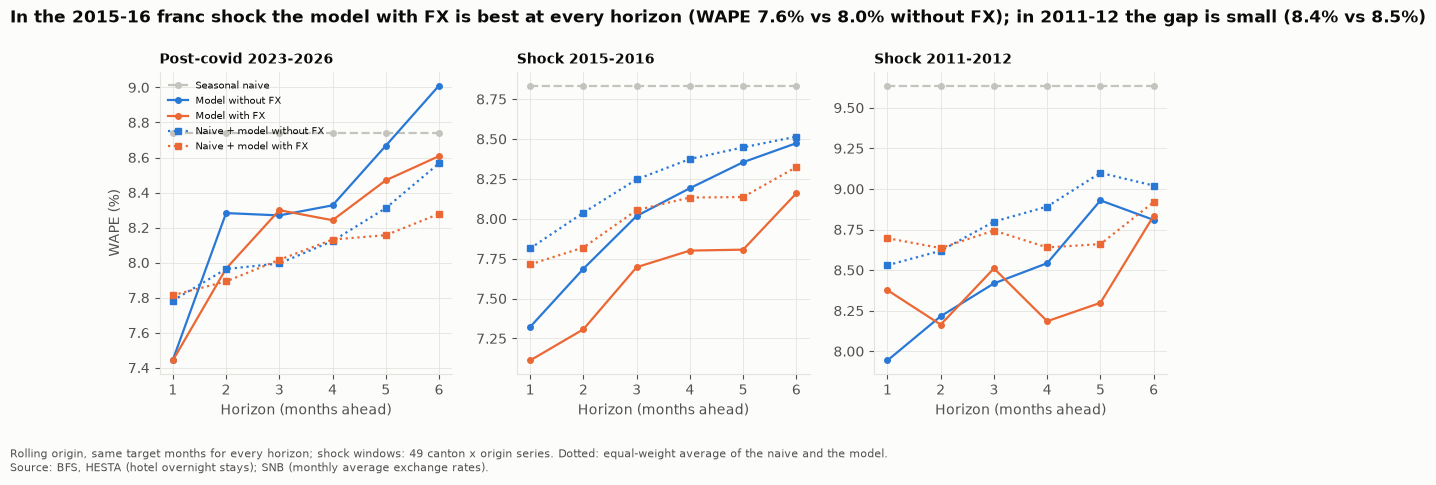

In [7]:
STYLE = {"naive": dict(color=GREY, ls="--"), "gb_no_fx": dict(color=SLOTS[0]), "gb_fx": dict(color=SLOTS[1]),
         "combo_no_fx": dict(color=SLOTS[0], ls=":", marker="s"), "combo_fx": dict(color=SLOTS[1], ls=":", marker="s")}
NAMES = {**fc.MODELS, **fc.COMBOS}
c15 = combo_h[combo_h["window"] == "shock_2015"]
assert (c15["gb_fx"] < c15[["naive", "gb_no_fx", "combo_no_fx", "combo_fx"]].min(axis=1)).all(), "title claim"
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
for ax, w in zip(axes, WIN):
    c = combo_h[combo_h["window"] == w]
    for col in ALL:
        kw = {"marker": "o", **STYLE[col]}
        ax.plot(c["h"], c[col], lw=1.6, ms=4, label=NAMES[col], **kw)
    ax.set_title(LABEL[w], loc="left", fontsize=10)
    ax.set_xticks(list(fc.HORIZONS))
    ax.set_xlabel("Horizon (months ahead)")
axes[0].set_ylabel("WAPE (%)")
axes[0].legend(fontsize=7, loc="upper left")
o15, o11 = overall.loc[(LABEL["shock_2015"], "all")], overall.loc[(LABEL["shock_2011"], "all")]
fig.suptitle(f"In the 2015-16 franc shock the model with FX is best at every horizon (WAPE {o15.gb_fx:.1f}% vs "
             f"{o15.gb_no_fx:.1f}% without FX); in 2011-12 the gap is small ({o11.gb_fx:.1f}% vs {o11.gb_no_fx:.1f}%)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
add_source(fig, SOURCE_BFS_SNB + ".", "Rolling origin, same target months for every horizon; shock windows: "
           "49 canton x origin series. Dotted: equal-weight average of the naive and the model.")
fig.subplots_adjust(bottom=0.22, top=0.85, wspace=0.22)
save(fig, "13_shock_backtest")

### Chart 14 — Real FX gain vs the noise floor

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/14_noise_floor.png')

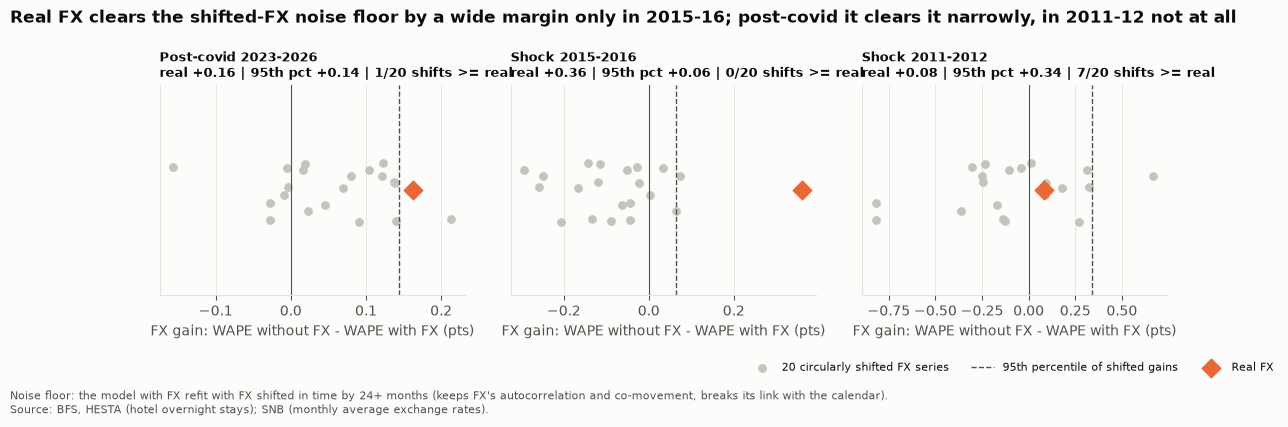

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, w in zip(axes, WIN):
    n = noise[w]
    ax.scatter(n["shift_gains"], np.random.default_rng(0).uniform(-0.3, 0.3, len(n["shift_gains"])),
               color=GREY, s=28, label="20 circularly shifted FX series", zorder=2)
    ax.axvline(n["shift_p95"], color=INK_SOFT, ls="--", lw=1, label="95th percentile of shifted gains")
    ax.scatter([n["real_gain"]], [0], color=SLOTS[1], s=90, marker="D", label="Real FX", zorder=3)
    ax.axvline(0, color=INK_SOFT, lw=0.8)
    ax.set_ylim(-1, 1); ax.set_yticks([])
    ax.grid(axis="y", visible=False)
    n_above = int((n["shift_gains"] >= n["real_gain"]).sum())
    ax.set_title(f"{LABEL[w]}\nreal {n['real_gain']:+.2f} | 95th pct {n['shift_p95']:+.2f} | "
                 f"{n_above}/20 shifts >= real", loc="left", fontsize=9)
    ax.set_xlabel("FX gain: WAPE without FX - WAPE with FX (pts)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, fontsize=8, loc="lower right", ncol=3, frameon=False, bbox_to_anchor=(0.99, 0.09))
fig.suptitle("Real FX clears the shifted-FX noise floor by a wide margin only in 2015-16; "
             "post-covid it clears it narrowly, in 2011-12 not at all",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
add_source(fig, SOURCE_BFS_SNB + ".", "Noise floor: the model with FX refit with FX shifted in time by 24+ months "
           "(keeps FX's autocorrelation and co-movement, breaks its link with the calendar).")
fig.subplots_adjust(bottom=0.3, top=0.8, wspace=0.15)
save(fig, "14_noise_floor")

### Chart 15 — FX gain by origin market vs its noise floor

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/15_fx_gain_by_market.png')

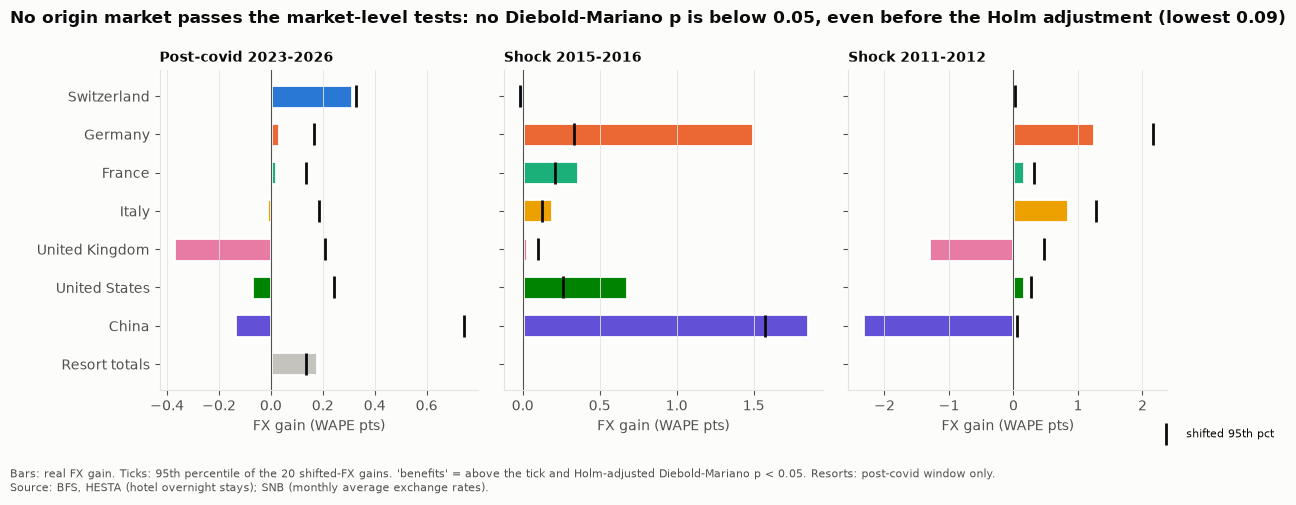

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5), sharey=True)
order = [m for m in MARKET_ORDER]
for ax, w in zip(axes, WIN):
    t = markets[markets["window"] == w].set_index("market").reindex(order)
    y = np.arange(len(order))[::-1]
    col = [GREY if m == "Resort totals" else ORIGIN_COLORS[m] for m in order]
    ax.barh(y, t["real_gain"], color=col, height=0.6, edgecolor="white", linewidth=2)
    ax.scatter(t["shift_p95"], y, marker="|", s=250, color=INK, zorder=3, label="shifted 95th pct")
    for yy, (m, r) in zip(y, t.iterrows()):
        if pd.notna(r["real_gain"]) and r["benefits"]:
            ax.annotate("benefits", xy=(max(r["real_gain"], r["shift_p95"]), yy), xytext=(4, 0),
                        textcoords="offset points", va="center", fontsize=7, color=INK)
    ax.axvline(0, color=INK_SOFT, lw=0.8)
    ax.set_yticks(y, order)
    ax.grid(axis="y", visible=False)
    ax.set_title(LABEL[w], loc="left", fontsize=10)
    ax.set_xlabel("FX gain (WAPE pts)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, fontsize=8, loc="lower right", frameon=False, bbox_to_anchor=(0.99, 0.1))
n_ben = int(markets["benefits"].sum())
assert n_ben == 0 and markets["dm_p"].min() > 0.05, "headline below assumes no market passes"
fig.suptitle(f"No origin market passes the market-level tests: no Diebold-Mariano p is below 0.05, "
             f"even before the Holm adjustment (lowest {markets['dm_p'].min():.2f})",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
add_source(fig, SOURCE_BFS_SNB + ".", "Bars: real FX gain. Ticks: 95th percentile of the 20 shifted-FX gains. "
           "'benefits' = above the tick and Holm-adjusted Diebold-Mariano p < 0.05. Resorts: post-covid window only.")
fig.subplots_adjust(bottom=0.22, top=0.86, wspace=0.08)
save(fig, "15_fx_gain_by_market")

## Limitations

- **Few independent episodes.** Two shock windows (24 and 16 target months) and one calm window (43); rolling-origin forecasts overlap, so the effective sample is small.
- **20 circular shifts** give a coarse noise floor (smallest possible empirical p = 1/21 = 0.048); with a fixed series length, shifts are not fully independent.
- **Shock windows use 49 canton series only** (resorts start in 2013) and train on 6-10 years of history, less than the post-covid window.
- **Diebold-Mariano** pools series and horizons per market; with 16-43 months it has low power, and Holm makes it conservative.
- **Same model as part A** by design (no tuning); a different model could use FX differently. Results use scikit-learn's HistGradientBoostingRegressor, not LightGBM.
- **Associations only.** "FX improves the forecast" means the FX feature lowers out-of-sample error, not that the franc causes the change in demand.
- **Hotels only;** overbooking and nightly pricing remain out of scope.

## Summary check

Every number in the summary at the top must match the results above.

In [10]:
f1 = lambda x: f"{x:.1f}"
f2 = lambda x: f"{x:+.2f}"
f3 = lambda x: f"{x:.3f}"
def win_row(w):
    o, n = overall.loc[(LABEL[w], "all")], noise[w]
    return (f1(o.naive), f1(o.gb_no_fx), f1(o.gb_fx), f2(o.fx_gain), f2(n["shift_p95"]), f3(n["p_emp"]),
            n["pos_horizons"], n["fx_improves"])
mk = markets.set_index(["window", "market"])
c6 = combo_h[(combo_h["window"] == "post_covid") & (combo_h["h"] == 6)].iloc[0]
c15 = combo_h[combo_h["window"] == "shock_2015"]
checks = {
    "post-covid row": win_row("post_covid") == ('8.7', '8.3', '8.2', '+0.16', '+0.14', '0.095', 5, True),
    "shock 2015 row": win_row("shock_2015") == ('8.8', '8.0', '7.6', '+0.36', '+0.06', '0.048', 6, True),
    "shock 2011 row": win_row("shock_2011") == ('9.6', '8.5', '8.4', '+0.08', '+0.34', '0.381', 3, False),
    "2015 highest shifted gain": f2(noise["shock_2015"]["shift_max"]) == '+0.07',
    "2015 model with FX lowest at every h": bool((c15["gb_fx"] < c15[["naive", "gb_no_fx", "combo_no_fx", "combo_fx"]].min(axis=1)).all()),
    "2015 peak gain": f2(overall.loc[(LABEL["shock_2015"], "peak"), "fx_gain"]) == '+0.60',
    "2015 Germany": (f1(by_market["shock_2015"].loc["Germany", "gb_no_fx"]), f1(by_market["shock_2015"].loc["Germany", "gb_fx"]), f2(by_market["shock_2015"].loc["Germany", "fx_gain"])) == ('10.7', '9.2', '+1.49'),
    "post-covid 1 shift above real": int((noise["post_covid"]["shift_gains"] >= noise["post_covid"]["real_gain"]).sum()) == 1,
    "post-covid shifted median": f2(noise["post_covid"]["shift_median"]) == '+0.06',
    "2011 markets": tuple(f2(by_market["shock_2011"].loc[m, "fx_gain"]) for m in ["Germany", "Italy", "United Kingdom", "China"]) == ('+1.24', '+0.84', '-1.31', '-2.34'),
    "no market benefits": not markets["benefits"].any(),
    "lowest unadjusted DM p": f"{markets['dm_p'].min():.2f}" == '0.09',
    "post-covid combos help at h 2-6": [c.loc[c["combo_no_fx_helps"], "h"].tolist() for c in [combo_h[combo_h["window"] == "post_covid"]]][0] == [2, 3, 4, 5, 6] and combo_h[combo_h["window"] == "post_covid"].loc[lambda d: d["combo_fx_helps"], "h"].tolist() == [2, 3, 4, 5, 6],
    "post-covid h=6 combo FX / naive / model FX": (f1(c6.combo_fx), f1(c6.naive), f1(c6.gb_fx)) == ('8.3', '8.7', '8.6'),
    "combos never help in shocks": not combo_h[combo_h["window"] != "post_covid"][["combo_no_fx_helps", "combo_fx_helps"]].any().any(),
}

for name, ok in checks.items():
    print(f"{'OK  ' if ok else 'FAIL'} {name}")
assert checks and all(checks.values()), "the summary at the top no longer matches the results"
print(sorted(p.name for p in (Path.cwd().resolve().parent / "reports" / "figures").glob("1[3-5]_*.png")))

OK   post-covid row
OK   shock 2015 row
OK   shock 2011 row
OK   2015 highest shifted gain
OK   2015 model with FX lowest at every h
OK   2015 peak gain
OK   2015 Germany
OK   post-covid 1 shift above real
OK   post-covid shifted median
OK   2011 markets
OK   no market benefits
OK   lowest unadjusted DM p
OK   post-covid combos help at h 2-6
OK   post-covid h=6 combo FX / naive / model FX
OK   combos never help in shocks
['13_shock_backtest.png', '14_noise_floor.png', '15_fx_gain_by_market.png']
